In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from Graphs import Node, Edge, FlowGraph

In [3]:
plants = {"A": 8, "B": 5, "C": 3}           # machines available
warehouses = {"X": 5, "Y": 4, "Z": 3}       # machines required
cost = {                                    # transport cost per machine (€)
    "A": {"X": 50, "Y": 60, "Z": 30},
    "B": {"X": 60, "Y": 40, "Z": 20},
    "C": {"X": 40, "Y": 70, "Z": 30},
}

In [4]:
def show_solution(graph):
    plan = pd.DataFrame(0, index=[n for n, d in graph.nodes(data=True) if d["supply"]],
                        columns=[n for n, d in graph.nodes(data=True) if d["demand"]])
    for u, v, d in graph.edges(data=True):
        plan.loc[u, v] = round(d["flow"])
    plan["shipped"] = plan.sum(axis=1)
    plan["available"] = [graph.nodes[n]["supply"] for n in plan.index]
    display(plan)
    print("Total cost:", graph.result.objective, "€")


def draw_solution(graph, title):
    pos = {n: (d["x"], d["y"]) for n, d in graph.nodes(data=True)}
    colors = ["tab:blue" if d["supply"] else "tab:orange" for _, d in graph.nodes(data=True)]
    used = [(u, v) for u, v, d in graph.edges(data=True) if d["flow"] > 0]
    unused = [(u, v) for u, v, d in graph.edges(data=True) if d["flow"] == 0]
    labels = {(u, v): f"{d['flow']:.0f} × {d['variable_cost']:.0f}€" for u, v, d in graph.edges(data=True) if d["flow"] > 0}

    fig, ax = plt.subplots(figsize=(8, 6))
    nx.draw_networkx_nodes(graph, pos, node_color=colors, node_size=1500, ax=ax)
    nx.draw_networkx_labels(graph, pos, font_size=9, ax=ax)
    nx.draw_networkx_edges(graph, pos, edgelist=used, width=3, arrowsize=20, node_size=1500, ax=ax)
    nx.draw_networkx_edges(graph, pos, edgelist=unused, style="dashed", edge_color="lightgrey", arrowsize=15, node_size=1500, ax=ax)
    nx.draw_networkx_edge_labels(graph, pos, edge_labels=labels, label_pos=0.3, font_size=9, ax=ax)
    ax.set_title(f"{title} - total cost {graph.result.objective:.0f} €")
    ax.axis("off")
    plt.show()

In [5]:
plant_nodes = {p: Node(name=p, supply=s, type="plant", x=0, y=-i) for i, (p, s) in enumerate(plants.items())}
warehouse_nodes = {w: Node(name=w, demand=d, type="warehouse", x=1, y=-i) for i, (w, d) in enumerate(warehouses.items())}

edges = [Edge(origin=plant_nodes[p], destination=warehouse_nodes[w], variable_cost=cost[p][w])
         for p in plants for w in warehouses]

graph = FlowGraph(list(plant_nodes.values()) + list(warehouse_nodes.values()), edges)
status = graph.min_cost_flow(integer=True)

Model creation time: 0.00 s
Optimal solution found: 460.00 in 0.10 s


,X,Y,Z,shipped,available
A,2,0,2,4,8.0
B,0,4,1,5,5.0
C,3,0,0,3,3.0


Total cost: 460.0 €


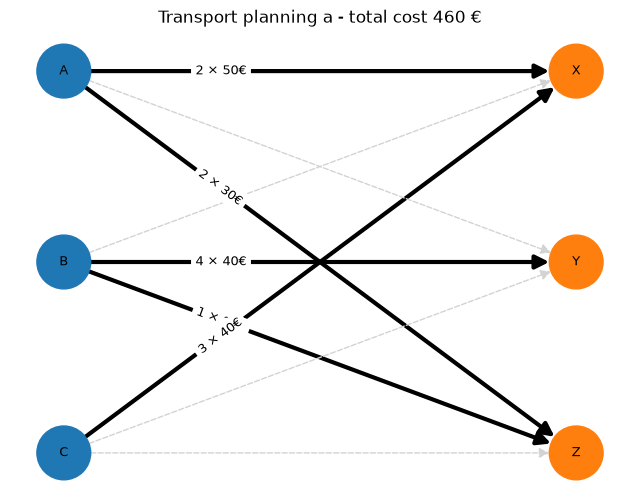

In [6]:
if status == "Optimal":
    show_solution(graph)
    draw_solution(graph, "Transport planning a")

In [7]:
# Plant B is split into two source nodes: the first 3 machines at the normal cost,
# the rest (4th, 5th) at +10 € per machine on every route
extra_cost = 10
first_machines_b = 3

plants_b = {"A": 8, "B": first_machines_b, "B_extra": plants["B"] - first_machines_b, "C": 3}
cost_b = dict(cost, B_extra={w: c + extra_cost for w, c in cost["B"].items()})

ys = {"A": 0, "B": -1, "B_extra": -1.5, "C": -2.5}   # positions for the plot
plant_nodes_b = {p: Node(name=p, supply=s, type="plant", x=0, y=ys[p]) for p, s in plants_b.items()}
warehouse_nodes_b = {w: Node(name=w, demand=d, type="warehouse", x=1, y=-1.25 * i) for i, (w, d) in enumerate(warehouses.items())}

edges_b = [Edge(origin=plant_nodes_b[p], destination=warehouse_nodes_b[w], variable_cost=cost_b[p][w])
           for p in plants_b for w in warehouses]

graph_b = FlowGraph(list(plant_nodes_b.values()) + list(warehouse_nodes_b.values()), edges_b)
status_b = graph_b.min_cost_flow(integer=True)

Model creation time: 0.00 s
Optimal solution found: 480.00 in 0.03 s


,X,Y,Z,shipped,available
A,2,0,3,5,8.0
B,0,3,0,3,3.0
B_extra,0,1,0,1,2.0
C,3,0,0,3,3.0


Total cost: 480.0 €
Machines shipped from plant B: 4.0


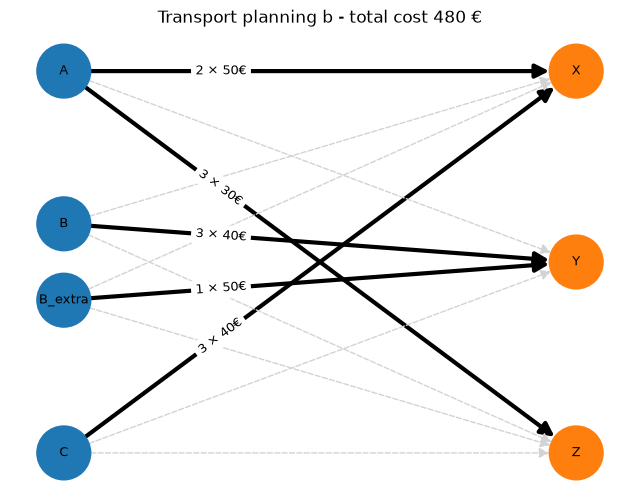

In [8]:
if status_b == "Optimal":
    show_solution(graph_b)
    machines_from_b = sum(graph_b.edges["B", w]["flow"] + graph_b.edges["B_extra", w]["flow"] for w in warehouses)
    print("Machines shipped from plant B:", machines_from_b)
    draw_solution(graph_b, "Transport planning b")